In [2]:
import sympy as sp 
import numpy as np
import matplotlib.pyplot as plt


## Equations différentielles ordinaires d'ordre 1
On va ici parler des équation de la forme ${X'(t)} = F({X(t)})$ où $F:\mathbb{X}^n \rightarrow \mathbb{K}^n$ est appellée un champ de vecteur autonome car ne dépendant pas du temps.

On peut parfois écrire une équation différentielle ordinaire d'ordre de p $\in$ $\mathbb{N_+}$ comme une équation d'ordre 1:

$x^{(p)} + a_{p-1}x^{(p-1)} + \dots + a_1 x' + a_0 x = f(x)$ dans certains cas il  existe $F:\mathbb{K}^n \rightarrow \mathbb{K}^n$ telle que ${X'(t)} = F({X(t)})$ .

${X(t)} = \begin{pmatrix} \overset{(1)\hspace{-5pt}}{x} \\ ... \\ \overset{(p-1)\hspace{-5pt}}{x}\end{pmatrix}$


### Equations différentielles affines
Nous allons commencer par traiter les équations différentielles affines du premier ordre de la forme ${X'(t)} = A(t){X(t)} + {B(t)}$  $\small{(1)}$

avec ${A(.)} \in  M_n(\mathbb{K})$ et ${X(t)}, {B(.)} \in \mathbb{K}^n$ 

#### Résolution des équations différentielles linéaires autonomes
Ce sont des cas particulier de $(1)$ où l'application linéaire ${A(.)}$ est constante et ${B(.)}=0$. Dans ce cas particulier là on peut résoudre analytiquement ces équations.

On a l'équation suivante ${X'(t)} = A{X(t)}$. 

Un exemple serait un circuit RLC, 

![photo circuit RLC](https://tse4.mm.bing.net/th/id/OIP.HCWPNtrCG6ROlDbpnH-VlQHaD5?r=0&pid=Api)

l'équation canonique est  $$\frac{d^2 {U_c}}{dt^2} + RC \frac{d {U_c}}{dt} + \frac{1}{LC}{U_c} = 0$$

On a donc la relation suivante $${X'(t)}= \begin{pmatrix} \frac{d{U_c}}{dt} \\ \frac{d²{U_c}}{dt²}  \end{pmatrix} = \begin{pmatrix} 0 & 1 \\ -\frac{1}{LC} & -\frac{R}{L} \end{pmatrix} \begin{pmatrix} {U_c} \\ \frac{d{U_c}}{dt}  \end{pmatrix} $$

On est ici dans un cas particulier où nous sommmes passer d'une équation d'ordre $p$ à une équation d'ordre 1 !

In [3]:
r,c,l =sp.symbols("R,C,L")
t,uc = sp.symbols("t,Uc")
uc0,duc0 = sp.symbols("Uc_0,Uc'")
A = sp.Matrix([[0,1],[-1/(c*l),-r/l ]])
sp.init_printing()




Maintenant on va essayer de résoudre cela en diagonalisant la matrice $A$, ce qu'on va faire c'est un changement de base pour se ramener à une matrice diagonale.

$A = P^{-1} D P$ le système est maintenant équivalent à ${PX'(t)} = DP{X(t)}$ ainsi en posant $ Y(t) = PX(t) \iff Y'(t) = DY(t)$ le système devient très simple à résoudre, en effet les solutions seront : $$Y(t) = \begin{pmatrix} e^{\lambda}y_1(0) \\ e^{\mu}y_1(0)  \end{pmatrix}$$ où $\lambda$ et $\mu$ sont les valeurs propres de $D$

Ensuite il nous restera juste à multiplier $Y(t)$ par la matrice de passage $P^{-1}$

In [5]:
P,D =A.diagonalize()
P_inv =P.inv()

lambd, mu = D[0,0],D[1,1]
#Calcul de y0
y0 = P_inv*sp.Matrix([[uc0],[duc0]])

#Solution dans la base du changement
M = sp.Matrix([[sp.exp(lambd*t),0],[0,sp.exp(mu*t)]])

#Retour dans la base initiale
X = sp.simplify(P*M*y0)
duc = sp.simplify(X[1])
uc = sp.simplify(X[0])

Cas $(\frac{R}{L})² - \frac{4}{LC} > 0$:

la valeur du delta est :  99600000000000.0


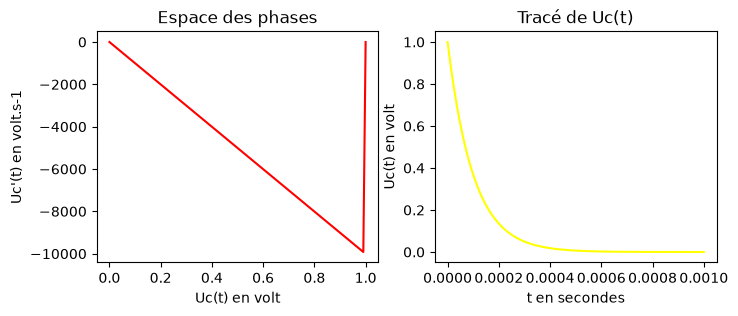

In [ ]:
values = {c:1e-7,l:1e-4,uc0:1,duc0:0,r:1000}
#calculer facteur qualité etc
uc_eval = uc.subs(values)
delta = (r/l)**2 - 4/(l*c)

print("la valeur du delta est : ",delta.subs(values))

time = np.linspace(0,0.001,1000)
uc_t = [sp.re(uc_eval.subs({t:i})) for i in time]


duc_eval = duc.subs(values)
duc_t = [sp.re(duc_eval.subs({t:i})) for i in time]
fig, ax = plt.subplots(nrows=1, ncols=2,figsize= (9,3))
ax[0].set_title("Espace des phases")
ax[0].set_xlabel("Uc(t) en volt")
ax[0].set_ylabel("Uc'(t) en volt.s-1")
ax[0].plot(uc_t,duc_t,color = "red")
ax[1].set_title("Tracé de Uc(t)")
ax[1].set_xlabel("t en secondes")
ax[1].set_ylabel("Uc(t) en volt")
ax[1].plot(time,uc_t, color = "yellow")

Cas $(\frac{R}{L})² - \frac{4}{LC} < 0$:

le delta vaut:  -30000000000.0000


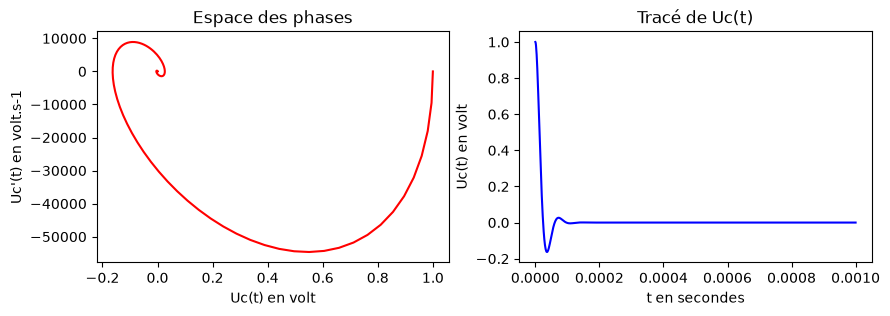

In [ ]:
values = {c:1e-7,l:1e-3,uc0:1,duc0:0,r:100}
uc_eval = uc.subs(values)
delta = (r/l)**2 - 4/(l*c)

print("le delta vaut: ",delta.subs(values))

time = np.linspace(0,0.001,1000)
uc_t = [sp.re(uc_eval.subs({t:i})) for i in time]

duc_eval = duc.subs(values)
duc_t = [sp.re(duc_eval.subs({t:i})) for i in time]

#plot
fig, ax = plt.subplots(nrows=1, ncols=2,figsize= (10,3))
ax[0].set_title("Espace des phases")
ax[0].set_xlabel("Uc(t) en volt")
ax[0].set_ylabel("Uc'(t) en volt.s-1")
ax[0].plot(uc_t,duc_t,color = "red")
ax[1].set_title("Tracé de Uc(t)")
ax[1].set_xlabel("t en secondes")
ax[1].set_ylabel("Uc(t) en volt")
ax[1].plot(time,uc_t, color = "blue")

Cas $(\frac{R}{L})² - \frac{4}{LC} = 0$:


Le delta vaut :  0


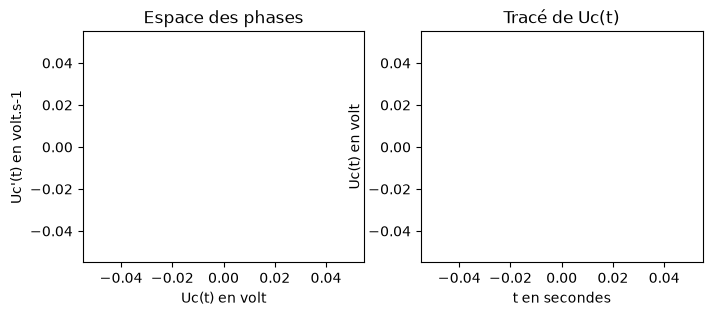

In [ ]:
values = {c:1e-7,l:1e-3,uc0:1,duc0:0,r:2e2}
#calculer facteur qualité etc
uc_eval = uc.subs(values)
delta = (r/l)**2 - 4/(l*c)

print("Le delta vaut : ",delta.subs(values))

time = np.linspace(0,0.001,1000)
uc_t = [sp.re(uc_eval.subs({t:i})) for i in time]
duc_eval = duc.subs(values)
duc_t = [sp.re(duc_eval.subs({t:i})) for i in time]

#Plot
fig, ax = plt.subplots(nrows=1, ncols=2,figsize= (9,3))
ax[0].set_title("Espace des phases")
ax[0].set_xlabel("Uc(t) en volt")
ax[0].set_ylabel("Uc'(t) en volt.s-1")
ax[0].plot(uc_t,duc_t,color = "red")
ax[1].set_title("Tracé de Uc(t)")
ax[1].set_xlabel("t en secondes")
ax[1].set_ylabel("Uc(t) en volt")
ax[1].plot(time,uc_t, color = "blue")

### Equations différentielles autonomes & générales

Retournons à notre cas général, le problème est qu'en général on ne sait pas tout le temps résoudre des équations différentielles. Cependant le champ de vecteurs $F$ lui peut nous fournir des informations qualitatives sur le comportements des solutions. Dans toutes cette partie on va supposer $F$ de classe $\mathcal{C¹}$ ou localement lipschitzienne. 

On a toujours cette équation:

$$ {X'(t)} = F({X(t)}) $$


On va introduire de nouvelles notions comme **le flot**  $\phi: \Omega = \left\{(t,m) \in \mathbb{R} \times U| t \in I_m  \right\}\rightarrow \phi _t(m)$  avec $\phi _t(m)$ la solution maximale associée à l'équation de donnée initiale $X(t_0) = m$ et $I_m$ l'ensemble de définition de la solution maximale. 

On va introduire **l'orbite** $\mathcal{O}_m = \left\{ \phi _t(m)| t \in I_m   \right\}$ qui est l'ensemble des valeurs prises par une solution maximale passant par le point $m$.  
**L'orbite** $\mathcal{O}_m $ peut être **périodique** si il existe $t_0 < t_1$ tels que $\phi _{t_0}(m) = \phi _{t_1}(m)$ **l'orbite** est alors homéomorphe à un cercle. Dans l'autre cas **l'orbite** peut être **non périodique**.

Ce qui nous ammènes au points **stationnaires** qui vérifient $ m \in U$ tel que $F(m) = 0 $ et on a $\mathcal{O}_m = \left\{ m \right\}$. A l'inverse les points **non stationnaires** vérifient $ m \in U$ tel que $F(m) \neq 0 $ son oribite ne contient **aucun point stationnaire** et $\mathcal{O}_m $ est une courbe paramétrique 

Puis pour finir nous allons introduire les **intégrales premières** : $h:U \rightarrow \mathbb{R} $ de classe $\mathcal{C¹}$ telle que la différentielle de h pour tout $m \in U$ soit nulle soit ${D_m}h(X(m)) = 0$.

Un théorème nous dit qu'en dimension n, il faudra n − 1 intégrales premières “indépendantes” pour déterminer de déterminer les orbites qui seront les points $m$ tels que pour tout $i \in [1,n]$,  ${D_m}h_i(X(m)) = 0$



Donnons-nous un exemple en dimension 2 et prenons le cas du système de Lotka Volterra: $$F(x,y) = \begin{pmatrix} x(y-1) \\ y(1-x) \end{pmatrix}$$  
avec $ x,y > 0$


/tmp/ipykernel_39808/701403659.py:7: RuntimeWarning: invalid value encountered in divide
  U_norm = U/norm
/tmp/ipykernel_39808/701403659.py:8: RuntimeWarning: invalid value encountered in divide
  V_norm = V/norm


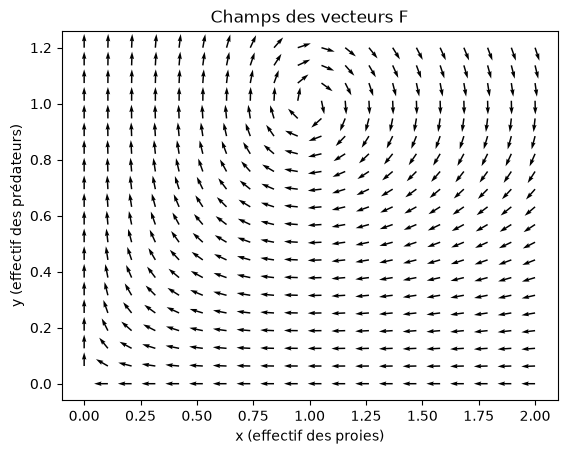

In [ ]:
x = np.linspace(0,2,20)
y = np.linspace(0,1.2,20)
X,Y = np.meshgrid(x,y)
U = X*(Y-1)
V = Y*(1-X)
norm = np.sqrt(U**2+V**2)
U_norm = U/norm
V_norm = V/norm
scale = 1

plt.quiver(X,Y,U_norm*scale, V_norm*scale,color = "black")
plt.title("Champs des vecteurs F")
plt.xlabel("x (effectif des proies)")
plt.ylabel("y (effectif des prédateurs)")
plt.show()

Dans notre cas on va pouvoir déjà commencer par trouver des points stationnaires qui sont en résolvant $\begin{pmatrix} 0 \\ 0 \end{pmatrix}=\begin{pmatrix} x(y-1) \\ y(1-x) \end{pmatrix}$,  les couples $(0,0)$ et $(1,1)$

On peut également montrer que $f(x,y) = ln(y)-y + ln(x)-x$ est une intégrale première du champ F, donc les orbites périodiques sont les ensembles tels que $f(x,y) = a \in \mathbb{R}$, on va pouvoir ainsi les tracer.
